# Práctica 2: Análisis Exploratorio de Datos y Preprocesamiento
Autores: Raúl Matellano y Jorge Palomino  
Grupo de laboratorio: 1321  
Pareja: 04  

Limpieza, tratamiento de nulos y análisis exploratorio del dataset residencial de Ames (Iowa) para preparar los datos de cara a futuros modelos de regresión.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1 y 2. Carga del conjunto de datos y exploración inicial
Cargamos `data.csv`. El dataset inicial cuenta con 1460 viviendas y 81 variables:
- 38 enteras (`int64`)
- 43 categóricas u objeto (`object`)
- 3 continuas (`float64`)

In [2]:
datos = pd.read_csv("data.csv")

display(datos.head())

print("Tipos de datos de las columnas:")
print(datos.dtypes)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Tipos de datos de las columnas:
Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object


## 3. Número de viviendas y recuento de valores nulos
Hay 1460 viviendas y 19 columnas con valores nulos.

Según `data-description.txt`, casi todos los NA indican ausencia física de la instalación (sin garaje, sin piscina, sin callejón) y no pérdidas accidentales de datos. Por eso no eliminamos filas con `dropna()`, sino que imputamos cada caso según su contexto.

In [3]:
total_viviendas = datos.shape[0]
print(f"Total de viviendas: {total_viviendas}")

recuento_nulos = datos.isnull().sum()
variables_con_nulos = recuento_nulos[recuento_nulos > 0].sort_values(ascending=False)

print("\nVariables con valores nulos:")
print(variables_con_nulos)

Total de viviendas: 1460

Variables con valores nulos:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


## 4. Estudio individual de variables

### Lote 1: Identificador, Tipo de Vivienda y Zonificación
- `Id`: Numérica secuencial (1 a 1460). Se elimina porque es un índice artificial sin poder predictivo que sobreajustaría los modelos.
- `MSSubClass`: Categórica nominal (20, 30, 60...). Representa tipologías de vivienda (1 planta, dúplex...). Se recodifica a `str` para evitar que el modelo asuma magnitudes aritméticas falsas.
- `MSZoning`: Categórica nominal sin nulos sobre uso del suelo. Se conserva por su impacto directo en el precio del terreno.

In [4]:
variables_lote1 = ['Id', 'MSSubClass', 'MSZoning']

for columna in variables_lote1:
    print(f"Variable: {columna}")
    print(f"Tipo: {datos[columna].dtype}")
    print(f"Nulos: {datos[columna].isnull().sum()}")
    print(f"Valores únicos: {datos[columna].nunique()}")
    print(f"Muestra de valores: {datos[columna].unique()[:8]}")
    if datos[columna].dtype in ['int64', 'float64']:
        print(f"Mín: {datos[columna].min()} | Máx: {datos[columna].max()}")
    else:
        print(f"Frecuencias:\n{datos[columna].value_counts()}")
    print()


Variable: Id
Tipo: int64
Nulos: 0
Valores únicos: 1460
Muestra de valores: [1 2 3 4 5 6 7 8]
Mín: 1 | Máx: 1460

Variable: MSSubClass
Tipo: int64
Nulos: 0
Valores únicos: 15
Muestra de valores: [ 60  20  70  50 190  45  90 120]
Mín: 20 | Máx: 190

Variable: MSZoning
Tipo: str
Nulos: 0
Valores únicos: 5
Muestra de valores: <StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str
Frecuencias:
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64



In [5]:
datos = datos.drop('Id', axis=1)
datos['MSSubClass'] = datos['MSSubClass'].astype(str)

print("Columna Id en datos:", 'Id' in datos.columns)
print("Tipo de MSSubClass:", datos['MSSubClass'].dtype)

Columna Id en datos: False
Tipo de MSSubClass: str


### Lote 2: Parcela y Accesos
- `LotFrontage`: Continua con 259 nulos (17.7%) y asimetría positiva. Imputamos con la mediana (69 pies) por ser robusta a outliers. Se conserva.
- `LotArea`: Continua sin nulos. Rango de 1.300 a 215.245 sq ft con outliers altos. Se conserva (conviene transformación logarítmica en regresión).
- `Street`: Categórica nominal sin nulos. El 99.6% es asfalto (`Pave`); tiene varianza casi nula pero la mantenemos de momento.
- `Alley`: Categórica con 1369 nulos (93.8%). Como NA indica ausencia de callejón, imputamos con 'Sin_Acceso'. Se conserva.
- `LotShape`: Ordinal sin nulos (`Reg`, `IR1`, `IR2`, `IR3`). Se conserva.

In [6]:
variables_lote2 = ['LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape']

for columna in variables_lote2:
    print(f"Variable: {columna}")
    print(f"Tipo: {datos[columna].dtype}")
    print(f"Nulos: {datos[columna].isnull().sum()}")
    print(f"Valores únicos: {datos[columna].nunique()}")
    print(f"Muestra de valores: {datos[columna].unique()[:6]}")
    if datos[columna].dtype in ['int64', 'float64']:
        print(f"Mín: {datos[columna].min()} | Máx: {datos[columna].max()} | Mediana: {datos[columna].median()}")
    else:
        print(f"Frecuencias:\n{datos[columna].value_counts(dropna=False)}")
    print()


Variable: LotFrontage
Tipo: float64
Nulos: 259
Valores únicos: 110
Muestra de valores: [65. 80. 68. 60. 84. 85.]
Mín: 21.0 | Máx: 313.0 | Mediana: 69.0

Variable: LotArea
Tipo: int64
Nulos: 0
Valores únicos: 1073
Muestra de valores: [ 8450  9600 11250  9550 14260 14115]
Mín: 1300 | Máx: 215245 | Mediana: 9478.5

Variable: Street
Tipo: str
Nulos: 0
Valores únicos: 2
Muestra de valores: <StringArray>
['Pave', 'Grvl']
Length: 2, dtype: str
Frecuencias:
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Variable: Alley
Tipo: str
Nulos: 1369
Valores únicos: 2
Muestra de valores: <StringArray>
[nan, 'Grvl', 'Pave']
Length: 3, dtype: str
Frecuencias:
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

Variable: LotShape
Tipo: str
Nulos: 0
Valores únicos: 4
Muestra de valores: <StringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str
Frecuencias:
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64



In [7]:
mediana_lot_frontage = datos['LotFrontage'].median()
datos['LotFrontage'] = datos['LotFrontage'].fillna(mediana_lot_frontage)

datos['Alley'] = datos['Alley'].fillna('Sin_Acceso')

print("Nulos restantes en LotFrontage:", datos['LotFrontage'].isnull().sum())
print("Nulos restantes en Alley:", datos['Alley'].isnull().sum())

Nulos restantes en LotFrontage: 0
Nulos restantes en Alley: 0


### Lote 3: Topografía, Suministros y Localización
- `LandContour`: Categórica nominal sin nulos (el 90% es llano `Lvl`). Se conserva.
- `Utilities`: Categórica con 1459 valores `AllPub` y solo 1 `NoSeWa`. Se elimina por varianza prácticamente nula.
- `LandSlope`: Ordinal sin nulos. El 94.7% tiene pendiente suave (`Gtl`). Se conserva para evaluar binarización.
- `Neighborhood`: Categórica nominal sin nulos con 25 barrios. Se conserva obligatoriamente por su peso en el precio del suelo.

In [8]:
variables_lote3 = ['LandContour', 'Utilities', 'LandSlope', 'Neighborhood']

for columna in variables_lote3:
    print(f"Variable: {columna}")
    print(f"Tipo: {datos[columna].dtype}")
    print(f"Nulos: {datos[columna].isnull().sum()}")
    print(f"Valores únicos: {datos[columna].nunique()}")
    print(f"Frecuencias:\n{datos[columna].value_counts()}")
    print()


Variable: LandContour
Tipo: str
Nulos: 0
Valores únicos: 4
Frecuencias:
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

Variable: Utilities
Tipo: str
Nulos: 0
Valores únicos: 2
Frecuencias:
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

Variable: LandSlope
Tipo: str
Nulos: 0
Valores únicos: 3
Frecuencias:
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

Variable: Neighborhood
Tipo: str
Nulos: 0
Valores únicos: 25
Frecuencias:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64



In [9]:
datos = datos.drop('Utilities', axis=1)

print("Columna Utilities en datos:", 'Utilities' in datos.columns)

Columna Utilities en datos: False


### Lote 4: Fechas de Construcción y Reforma
- `YearBuilt`: Temporal discreta (1872 a 2010). Sin nulos. Se conserva.
- `YearRemodAdd`: Temporal discreta (1950 a 2010). Sin nulos ni incoherencias respecto a `YearBuilt`. Se conserva.

In [10]:
variables_lote4 = ['YearBuilt', 'YearRemodAdd']

for columna in variables_lote4:
    print(f"Variable: {columna}")
    print(f"Tipo: {datos[columna].dtype}")
    print(f"Nulos: {datos[columna].isnull().sum()}")
    print(f"Mín: {datos[columna].min()} | Máx: {datos[columna].max()} | Mediana: {datos[columna].median()}")
    print(f"Valores únicos: {datos[columna].nunique()}")
    print()

reformas_incoherentes = datos[datos['YearRemodAdd'] < datos['YearBuilt']]
print("Casos con YearRemodAdd < YearBuilt:", len(reformas_incoherentes))

Variable: YearBuilt
Tipo: int64
Nulos: 0
Mín: 1872 | Máx: 2010 | Mediana: 1973.0
Valores únicos: 112

Variable: YearRemodAdd
Tipo: int64
Nulos: 0
Mín: 1950 | Máx: 2010 | Mediana: 1994.0
Valores únicos: 61

Casos con YearRemodAdd < YearBuilt: 0


### Lote 5: Variables de Garaje
- Las variables cualitativas y `GarageYrBlt` tienen exactamente 81 nulos, que coinciden con `GarageCars == 0` y `GarageArea == 0` (casas sin garaje).
- Tratamiento: Imputamos las categóricas con 'Sin_Garaje' y `GarageYrBlt` con 0 para mantener el tipo numérico.
- `GarageCars` y `GarageArea` no tienen nulos y se conservan, teniendo en cuenta que son muy colineales (r aprox. 0.88).

In [11]:
variables_garaje = ['GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'GarageType', 'GarageYrBlt', 'GarageFinish']

for columna in variables_garaje:
    info = f"{columna} - Tipo: {datos[columna].dtype}, Nulos: {datos[columna].isnull().sum()}, Únicos: {datos[columna].nunique()}"
    if datos[columna].dtype in ['int64', 'float64']:
        info += f", Mín: {datos[columna].min()}, Máx: {datos[columna].max()}"
    print(info)

filas_sin_garaje = datos[(datos['GarageCars'] == 0) & (datos['GarageArea'] == 0)]
print("\nCasas con GarageCars == 0 y GarageArea == 0:", len(filas_sin_garaje))

GarageCars - Tipo: int64, Nulos: 0, Únicos: 5, Mín: 0, Máx: 4
GarageArea - Tipo: int64, Nulos: 0, Únicos: 441, Mín: 0, Máx: 1418
GarageQual - Tipo: str, Nulos: 81, Únicos: 5
GarageCond - Tipo: str, Nulos: 81, Únicos: 5
GarageType - Tipo: str, Nulos: 81, Únicos: 6
GarageYrBlt - Tipo: float64, Nulos: 81, Únicos: 97, Mín: 1900.0, Máx: 2010.0
GarageFinish - Tipo: str, Nulos: 81, Únicos: 3

Casas con GarageCars == 0 y GarageArea == 0: 81


In [12]:
columnas_garaje_categoricas = ['GarageQual', 'GarageCond', 'GarageType', 'GarageFinish']
for columna in columnas_garaje_categoricas:
    datos[columna] = datos[columna].fillna('Sin_Garaje')

datos['GarageYrBlt'] = datos['GarageYrBlt'].fillna(0)

print("Nulos restantes en variables de garaje:")
print(datos[variables_garaje].isnull().sum())

Nulos restantes en variables de garaje:
GarageCars      0
GarageArea      0
GarageQual      0
GarageCond      0
GarageType      0
GarageYrBlt     0
GarageFinish    0
dtype: int64


### Lote 6: Calidades y Variable Objetivo
- `OverallQual`: Ordinal (1 a 10) sin nulos, mediana 6. Es el predictor individual más correlacionado con el precio.
- `OverallCond`: Ordinal (1 a 10) sin nulos, mediana 5. Se conserva.
- `SalePrice`: Variable continua objetivo. Rango entre 34.900 $ y 755.000 $ con asimetría positiva hacia precios altos. Se conserva.

In [13]:
variables_lote6 = ['OverallQual', 'OverallCond', 'SalePrice']

for columna in variables_lote6:
    print(f"Variable: {columna}")
    print(f"Tipo: {datos[columna].dtype}")
    print(f"Nulos: {datos[columna].isnull().sum()}")
    print(f"Valores únicos ({datos[columna].nunique()}): {sorted(datos[columna].unique())[:10]}")
    if datos[columna].dtype in ['int64', 'float64']:
        print(f"Mín: {datos[columna].min()} | Máx: {datos[columna].max()} | Mediana: {datos[columna].median()}")
    print()


Variable: OverallQual
Tipo: int64
Nulos: 0
Valores únicos (10): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Mín: 1 | Máx: 10 | Mediana: 6.0

Variable: OverallCond
Tipo: int64
Nulos: 0
Valores únicos (9): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Mín: 1 | Máx: 9 | Mediana: 5.0

Variable: SalePrice
Tipo: int64
Nulos: 0
Valores únicos (663): [np.int64(34900), np.int64(35311), np.int64(37900), np.int64(39300), np.int64(40000), np.int64(52000), np.int64(52500), np.int64(55000), np.int64(55993), np.int64(58500)]
Mín: 34900 | Máx: 755000 | Mediana: 163000.0



## 5. Comprobaciones estadísticas finales
1. Número de viviendas: Sigue siendo 1460. No ha variado porque no se han eliminado filas; los nulos eran ausencias físicas imputadas y solo se han descartado columnas irrelevantes (`Id`, `Utilities`).
2. Tabla comparativa: Las variables tratadas pasan a tener 0 nulos y `Utilities` se marca como eliminada.

In [14]:
print("Casas iniciales:", total_viviendas)
print("Casas actuales:", len(datos))

tabla_comparativa_nulos = pd.DataFrame({
    'Columna': ['LotFrontage', 'Alley', 'Utilities', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond'],
    '#Missing values anteriores': [259, 1369, 0, 81, 81, 81, 81, 81],
    '#Missing values actual': [
        datos['LotFrontage'].isnull().sum(),
        datos['Alley'].isnull().sum(),
        "Eliminada",
        datos['GarageType'].isnull().sum(),
        datos['GarageYrBlt'].isnull().sum(),
        datos['GarageFinish'].isnull().sum(),
        datos['GarageQual'].isnull().sum(),
        datos['GarageCond'].isnull().sum()
    ]
})

display(tabla_comparativa_nulos)

Casas iniciales: 1460
Casas actuales: 1460


,Columna,#Missing values anteriores,#Missing values actual
0,LotFrontage,259,0
1,Alley,1369,0
2,Utilities,0,Eliminada
3,GarageType,81,0
4,GarageYrBlt,81,0
5,GarageFinish,81,0
6,GarageQual,81,0
7,GarageCond,81,0


## 6. Distribuciones y toma de decisiones

### Histogramas:
- `SalePrice` y `LotArea`: Tienen asimetría positiva hacia la derecha y valores atípicos muy altos. Conviene aplicarles una transformación logarítmica para los modelos de regresión lineal.
- `LotFrontage`: Distribución bastante centrada en torno a los 69 pies, con una ligera cola hacia valores altos.
- `OverallQual`: Distribución centrada en las notas 5 y 6.

### Decisiones (Donuts):
- `LandSlope`: El 94.7% es llano (`Gtl`). Al no tener apenas variación, se puede binarizar (1 si es `Gtl` y 0 si no) o incluso descartar.
- `Neighborhood`: Repartida en 25 barrios. Es una variable clave para el precio del suelo, por lo que se mantiene para codificar en el modelado.
- `Utilities`: Al tener el 99.93% de casas el mismo valor, se confirma su eliminación.

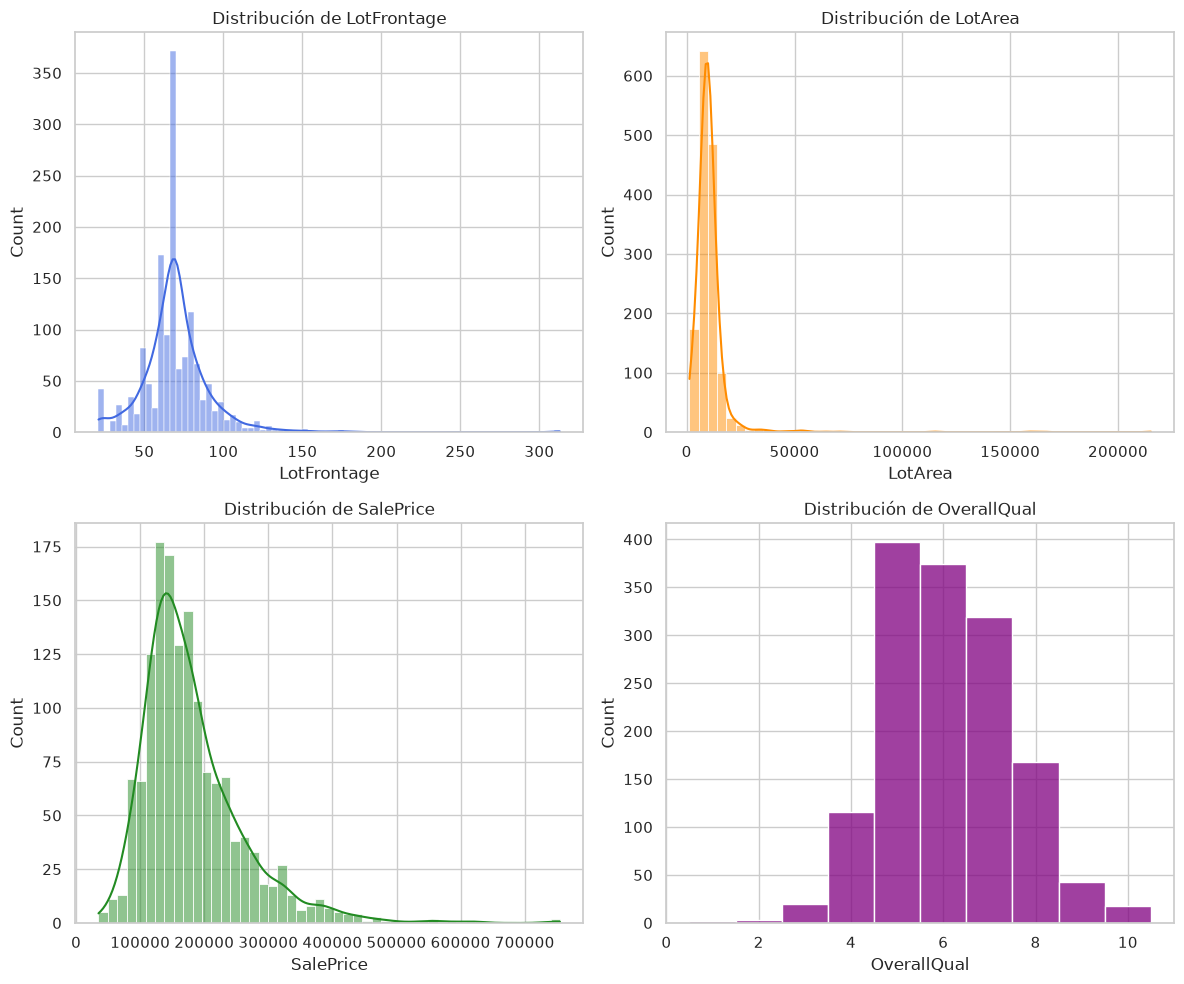

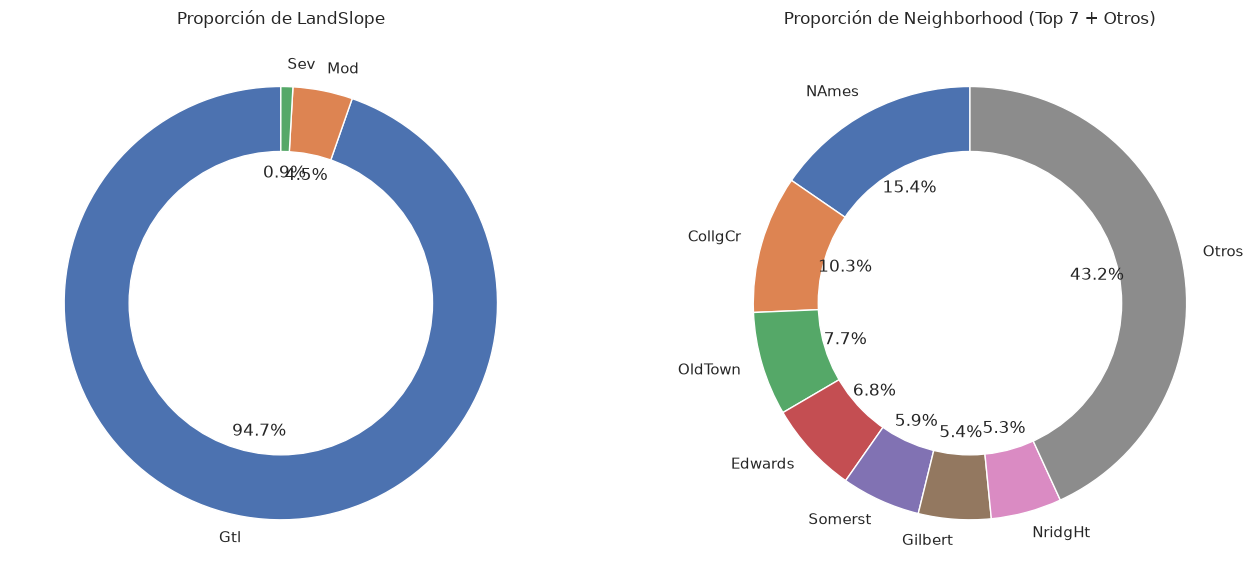

In [15]:
figura_histogramas, ejes_histogramas = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(datos['LotFrontage'], kde=True, ax=ejes_histogramas[0, 0], color='royalblue')
ejes_histogramas[0, 0].set_title('Distribución de LotFrontage')

sns.histplot(datos['LotArea'], kde=True, bins=50, ax=ejes_histogramas[0, 1], color='darkorange')
ejes_histogramas[0, 1].set_title('Distribución de LotArea')

sns.histplot(datos['SalePrice'], kde=True, ax=ejes_histogramas[1, 0], color='forestgreen')
ejes_histogramas[1, 0].set_title('Distribución de SalePrice')

sns.histplot(datos['OverallQual'], discrete=True, ax=ejes_histogramas[1, 1], color='purple')
ejes_histogramas[1, 1].set_title('Distribución de OverallQual')

plt.tight_layout()
plt.show()

figura_donuts, ejes_donuts = plt.subplots(1, 2, figsize=(14, 6))

frecuencias_land_slope = datos['LandSlope'].value_counts()
ejes_donuts[0].pie(frecuencias_land_slope, labels=frecuencias_land_slope.index, autopct='%1.1f%%', startangle=90)
circulo_centro_slope = plt.Circle((0, 0), 0.70, color='white')
ejes_donuts[0].add_artist(circulo_centro_slope)
ejes_donuts[0].set_title('Proporción de LandSlope')

total_barrios_principales = 7
frecuencias_neighborhood = datos['Neighborhood'].value_counts()
barrios_principales = frecuencias_neighborhood[:total_barrios_principales]
barrios_otros = pd.Series({'Otros': frecuencias_neighborhood[total_barrios_principales:].sum()})
datos_donut_neighborhood = pd.concat([barrios_principales, barrios_otros])

ejes_donuts[1].pie(datos_donut_neighborhood, labels=datos_donut_neighborhood.index, autopct='%1.1f%%', startangle=90)
circulo_centro_neighborhood = plt.Circle((0, 0), 0.70, color='white')
ejes_donuts[1].add_artist(circulo_centro_neighborhood)
ejes_donuts[1].set_title('Proporción de Neighborhood (Top 7 + Otros)')

plt.tight_layout()
plt.show()

## 7. Matriz de correlación y Clustermap
1. Predictores más correlacionados con `SalePrice`: `OverallQual` (r = 0.79) y `GrLivArea` (r = 0.71), seguidos de garaje (`GarageCars`: 0.64, `GarageArea`: 0.62) y sótano/planta baja (`TotalBsmtSF`: 0.61, `1stFlrSF`: 0.61).
2. Multicolinealidad en clusters:
   - `GarageCars` y `GarageArea` (r aprox. 0.88)
   - `TotalBsmtSF` y `1stFlrSF` (r aprox. 0.82)
   - `GrLivArea` y `TotRmsAbvGrd` (r aprox. 0.83)
   - `YearBuilt` y `GarageYrBlt` (r aprox. 0.83)
3. Implicaciones para el modelado: Mantener pares colineales desestabiliza los coeficientes en regresión lineal. Conviene descartar una variable de cada par redundante o aplicar regularización (Ridge/Lasso).

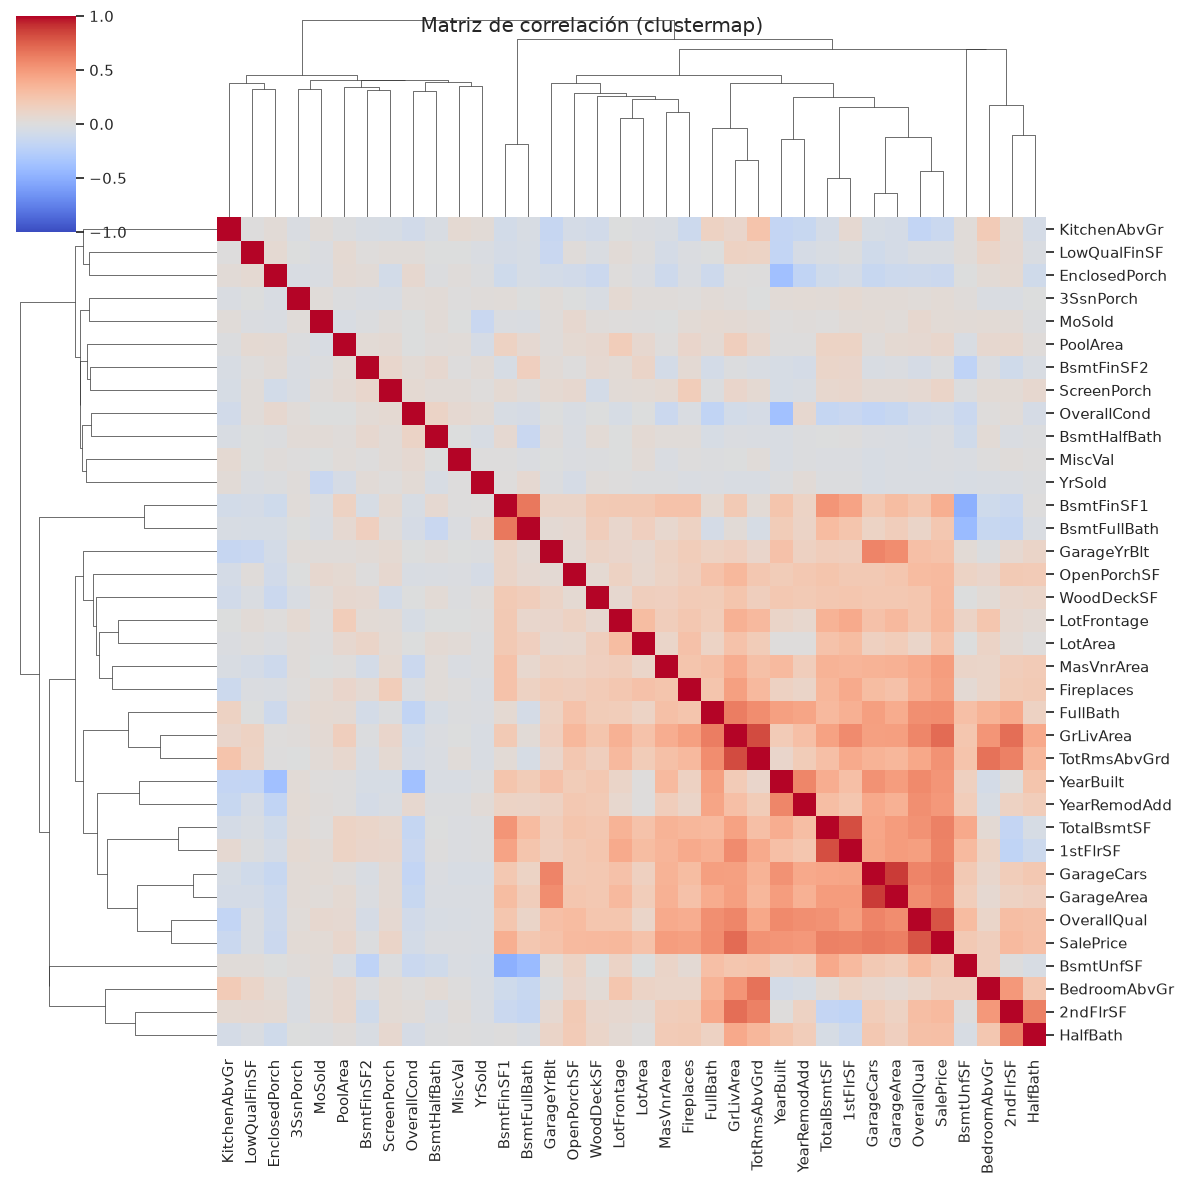

Top 10 variables con mayor correlación con SalePrice:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [16]:
columnas_numericas = datos.select_dtypes(include=['int64', 'float64']).columns
matriz_correlacion = datos[columnas_numericas].corr()

grafico_clustermap = sns.clustermap(
    matriz_correlacion, 
    cmap='coolwarm', 
    figsize=(12, 12), 
    vmin=-1, vmax=1, 
    annot=False
)
grafico_clustermap.fig.suptitle("Matriz de correlación (clustermap)")
plt.show()

correlacion_precio = matriz_correlacion['SalePrice'].sort_values(ascending=False)
print("Top 10 variables con mayor correlación con SalePrice:")
print(correlacion_precio.head(11))